In [19]:
# %pip install pandas numpy matplotlib seaborn scikit-learn
# %pip install matplotlib

In [20]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.preprocessing import LabelEncoder , MinMaxScaler , StandardScaler
import os

In [10]:
pwd

'C:\\pushkar\\data analytics project'

In [11]:
TR = pd.read_csv('Travel.csv')

In [12]:
TR.head(1)

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0


In [13]:
TR.dtypes

CustomerID                    int64
ProdTaken                     int64
Age                         float64
TypeofContact                object
CityTier                      int64
DurationOfPitch             float64
Occupation                   object
Gender                       object
NumberOfPersonVisiting        int64
NumberOfFollowups           float64
ProductPitched               object
PreferredPropertyStar       float64
MaritalStatus                object
NumberOfTrips               float64
Passport                      int64
PitchSatisfactionScore        int64
OwnCar                        int64
NumberOfChildrenVisiting    float64
Designation                  object
MonthlyIncome               float64
dtype: object

In [14]:
#TR['age].astype(int) # found null values

In [15]:
TR.isnull().sum()

CustomerID                    0
ProdTaken                     0
Age                         226
TypeofContact                25
CityTier                      0
DurationOfPitch             251
Occupation                    0
Gender                        0
NumberOfPersonVisiting        0
NumberOfFollowups            45
ProductPitched                0
PreferredPropertyStar        26
MaritalStatus                 0
NumberOfTrips               140
Passport                      0
PitchSatisfactionScore        0
OwnCar                        0
NumberOfChildrenVisiting     66
Designation                   0
MonthlyIncome               233
dtype: int64

# mising value
1) Mean | Medium | Mode
2) Bfill | Ffill
3) Domain specific knowledge
4) Interpolation 

In [57]:
for col in TR.columns :
    if TR[col].dtypes!='object':
        TR[col]=TR[col].fillna(round(TR[col].mean()))
    else:
        TR[col]=TR[col].fillna(TR[col].mode()[0])


# for col in TR.columns:
#     if TR[col].dtype == 'object':
#         TR[col] = TR[col].fillna(TR[col].mode()[0])
#     else:
#         TR[col] = TR[col].fillna(round(TR[col].mean()))


In [58]:
TR.isnull().sum()

CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0
dtype: int64

In [59]:
# TR.['age'].astype(int)

In [60]:
TR['Age']=TR['Age'].astype(int)

In [61]:
TR.dtypes

CustomerID                   int64
ProdTaken                    int64
Age                          int64
TypeofContact               object
CityTier                     int64
DurationOfPitch              int64
Occupation                  object
Gender                      object
NumberOfPersonVisiting       int64
NumberOfFollowups            int64
ProductPitched              object
PreferredPropertyStar        int64
MaritalStatus               object
NumberOfTrips                int64
Passport                     int64
PitchSatisfactionScore       int64
OwnCar                       int64
NumberOfChildrenVisiting     int64
Designation                 object
MonthlyIncome                int64
dtype: object

In [62]:
for col in TR.columns:
    if col!='Monthlyincome' and TR[col].dtypes==float:
        TR[col]=TR[col].astype(int)

In [63]:
TR.dtypes

CustomerID                   int64
ProdTaken                    int64
Age                          int64
TypeofContact               object
CityTier                     int64
DurationOfPitch              int64
Occupation                  object
Gender                      object
NumberOfPersonVisiting       int64
NumberOfFollowups            int64
ProductPitched              object
PreferredPropertyStar        int64
MaritalStatus               object
NumberOfTrips                int64
Passport                     int64
PitchSatisfactionScore       int64
OwnCar                       int64
NumberOfChildrenVisiting     int64
Designation                 object
MonthlyIncome                int64
dtype: object

In [64]:
for col in TR.columns:
    if col!='MonthlyIncome' and TR[col].dtypes==float:
        TR[col] = TR[col].astype(int)

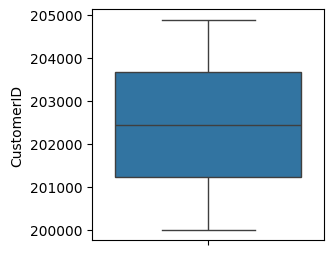

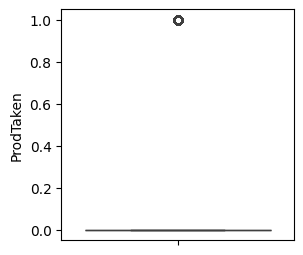

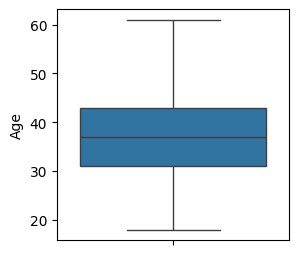

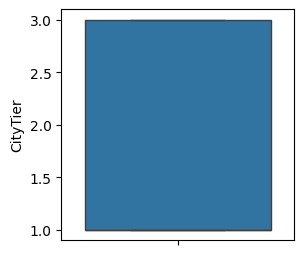

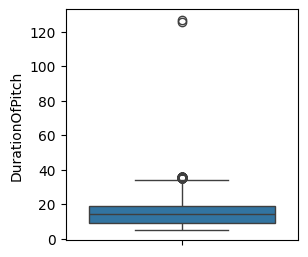

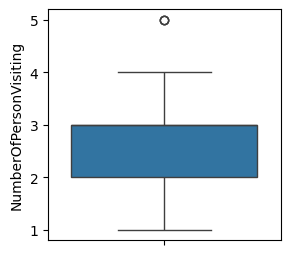

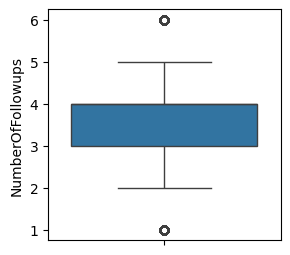

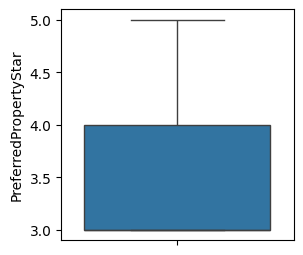

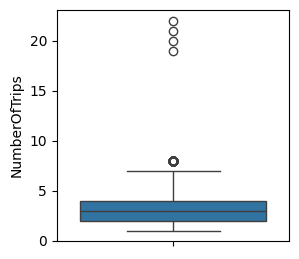

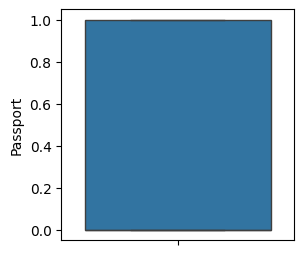

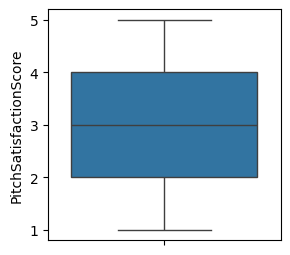

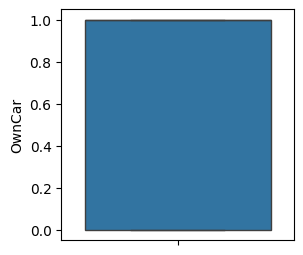

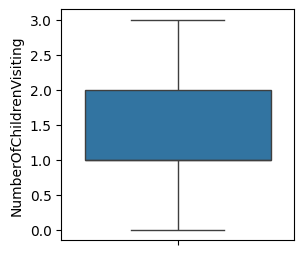

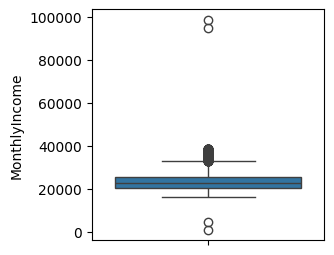

In [65]:
for col in TR.columns:
    if TR[col].dtypes!='object':
        plt.figure(figsize=(3,3))
        sns.boxplot(TR[col])
        plt.show()

In [66]:
TR1 = TR.copy()

IQR method

In [67]:
for col in TR1.columns:
    if TR1[col].dtypes!='object':
        Q1 = TR1[col].quantile(0.25)
        Q3 = TR1[col].quantile(0.75)
        IQR = Q3-Q1
        upper_fence = Q3+(1.5*IQR)
        lower_fence = Q1-(1.5*IQR)
        TR1 = TR1[TR1[col].between(lower_fence,upper_fence)]

In [68]:
TR1.shape[0] / TR.shape[0]

0.48731587561374795

In [69]:
TR1.shape[0] 

2382

# Z score method 

In [70]:
# emperical formula says if data is between -3 to +3 standard deviation 
# then 99.7% data is without outlier 

In [71]:
# step 1 [standardization of all numeric columns and will create a copy ]
# step2 [ apply filter of -3 to +3 standard deviation ]
# step3 [ drop all columns which are in standardize form]

In [72]:
TR2 = TR.copy()

In [74]:
for col in TR2.columns:
    if TR2[col].dtypes!='object':
        TR2[col+'STD']=StandardScaler().fit_transform(TR2[[col]])
        TR2 = TR2[TR2[col+'STD'].between(-3,3)]
        TR2 .drop(col+'STD',axis=1,inplace=True)

In [75]:
TR2.shape

(4878, 20)

In [76]:
TR2.shape[0] / TR.shape[0]

0.9979541734860884

In [77]:
TR.shape

(4888, 20)

# visualization 

In [78]:
# for categorical analysis using count plot to check 
# area of distribution between the categories

In [79]:
TR['Gender'].unique()

array(['Female', 'Male', 'Fe Male'], dtype=object)

In [80]:
TR2['Gender'] = TR2['Gender'].replace('Fe Male','Female')

In [81]:
sns.set_style('whitegrid')
palette=sns.color_palette('Purples',6)
for col in TR2.columns:
    if TR2[col].dtypes=='str':
        sns.countplot(x=TR2[col],palette=palette)
        plt.show()

In [82]:
palette

[(0.9265974625144175, 0.919769319492503, 0.9557093425605536),
 (0.8207612456747405, 0.8218992695117262, 0.9044982698961938),
 (0.6878892733564014, 0.6835832372164552, 0.829834678969627),
 (0.5513264129181085, 0.537916186082276, 0.7524490580545944),
 (0.440722798923491, 0.36772010765090346, 0.6653902345251825),
 (0.3405767012687428, 0.1742560553633218, 0.5709342560553633)]

In [83]:
TR2.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting',
       'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar',
       'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore',
       'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='object')

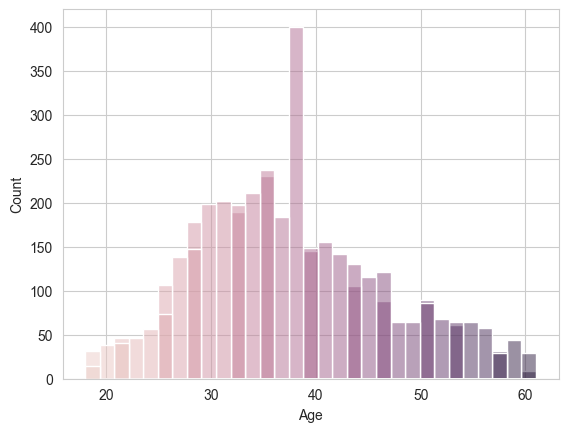

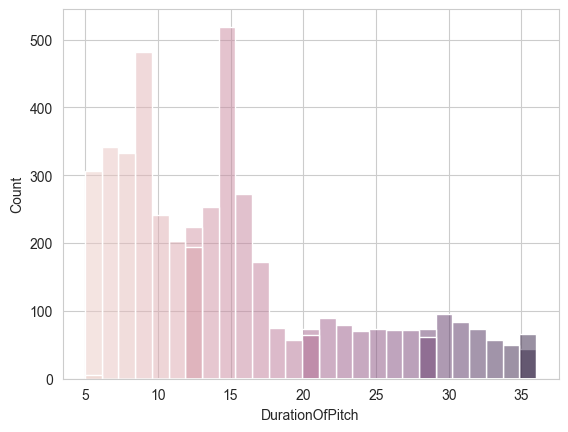

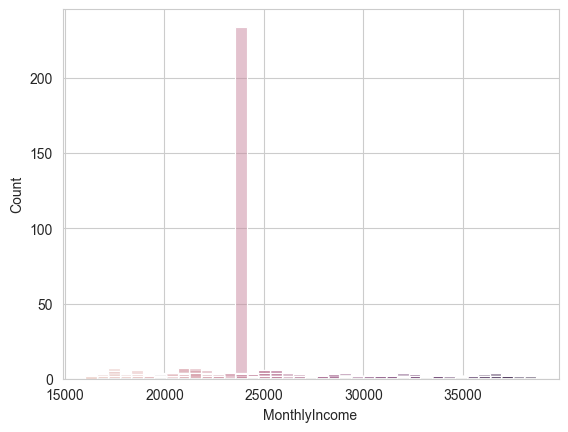

In [84]:
sns.set_style('whitegrid')
palette=sns.set_palette('Purples',6)
for col in TR2.columns:
    if col in ['MonthlyIncome','DurationOfPitch','Age']:
        sns.histplot(x=TR2[col],hue = TR2[col],palette=palette,legend=False)
        plt.show()

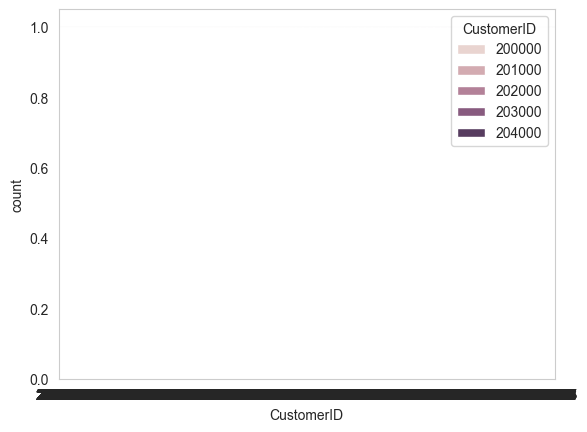

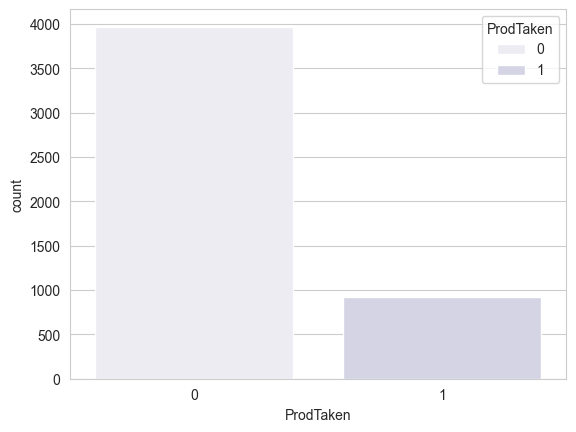

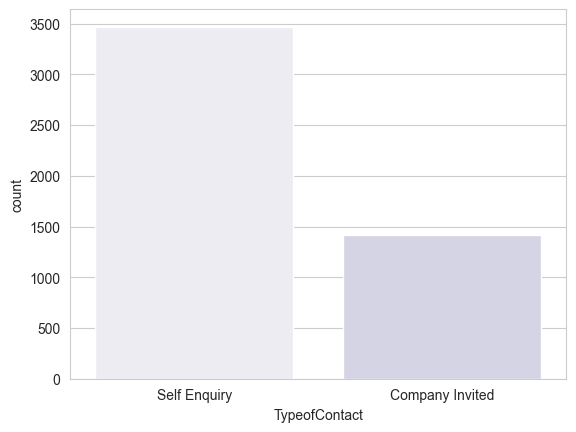

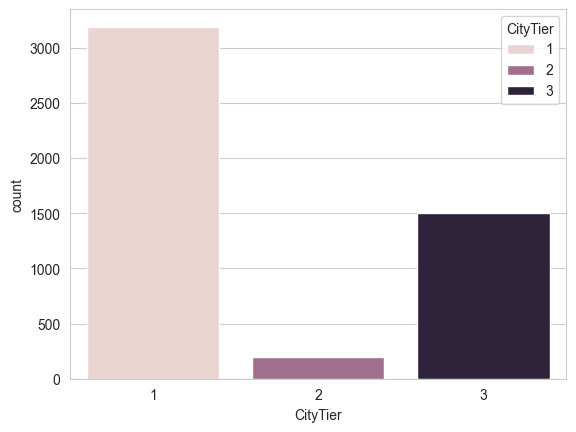

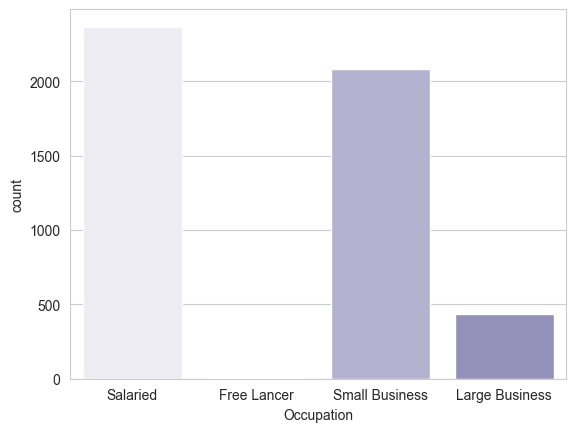

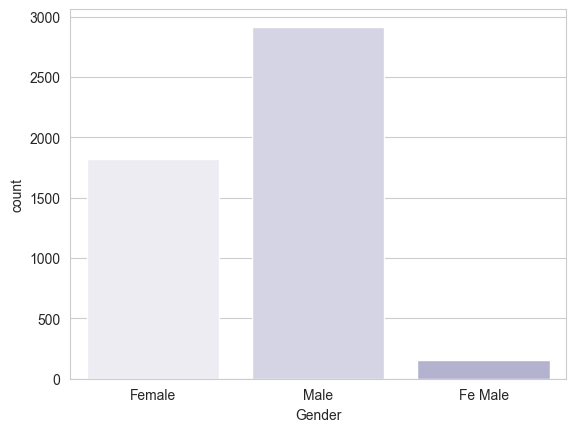

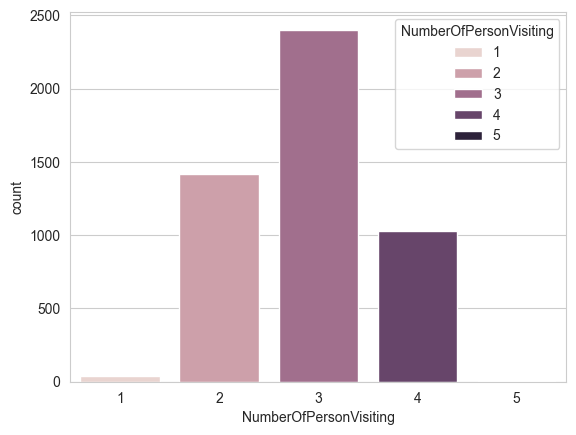

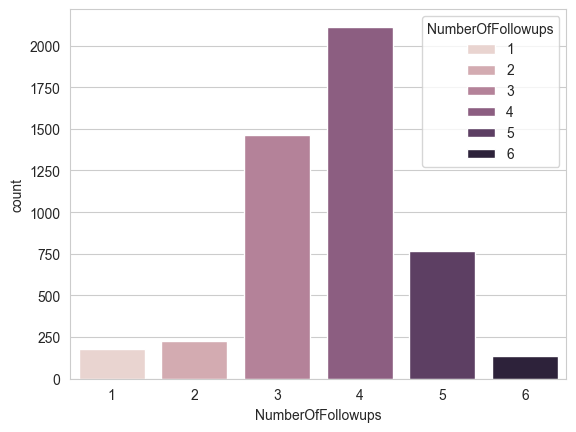

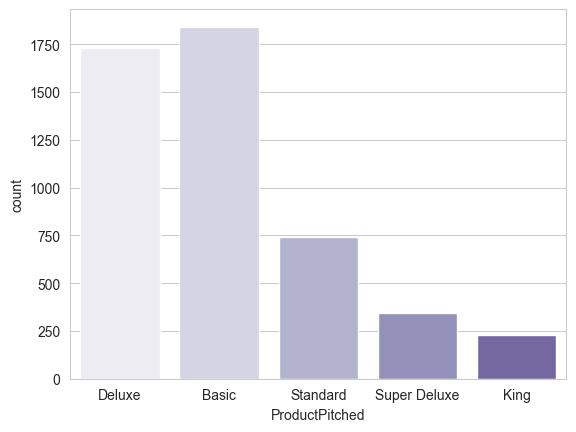

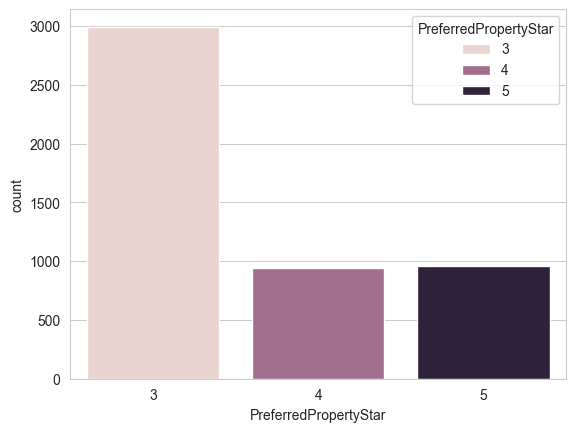

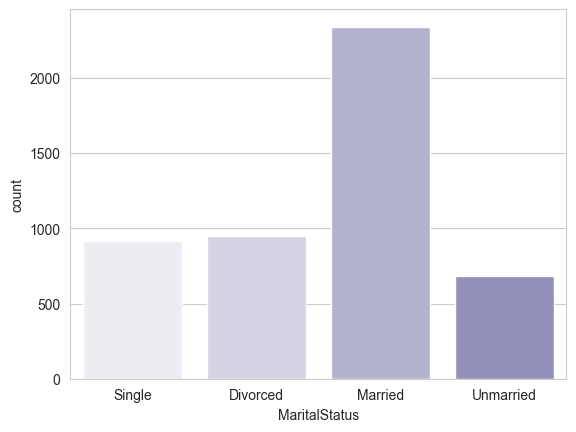

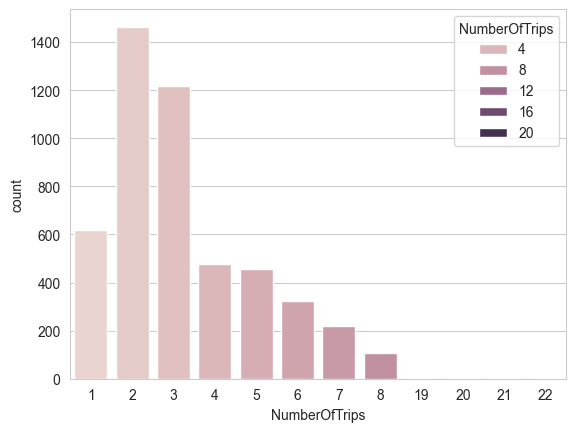

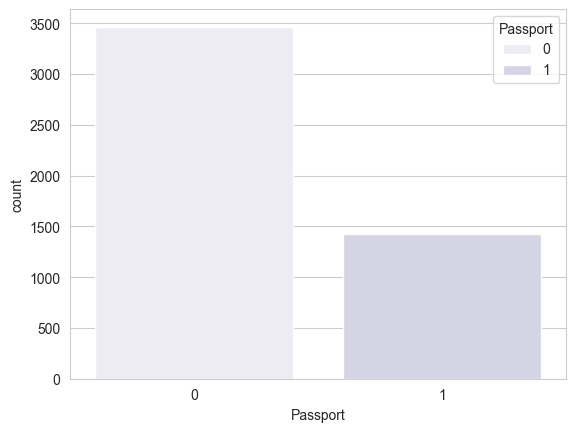

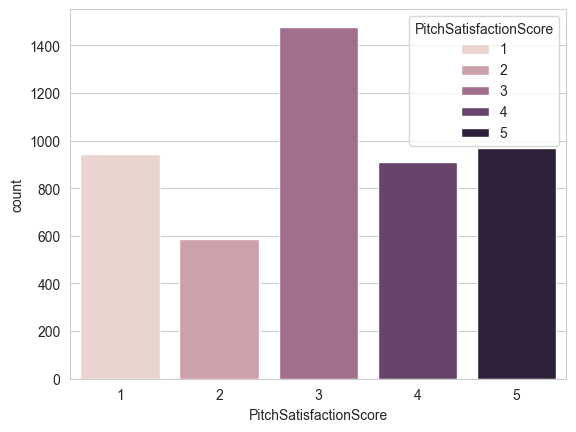

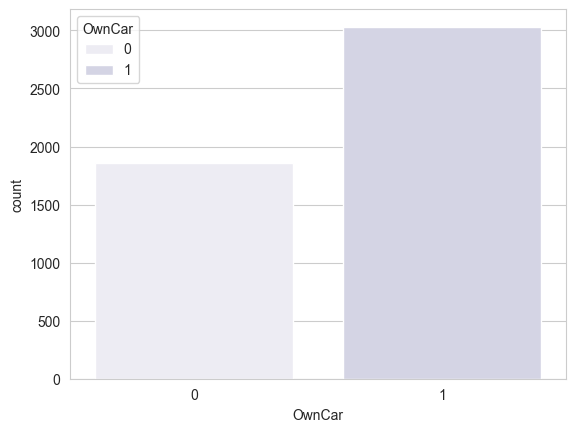

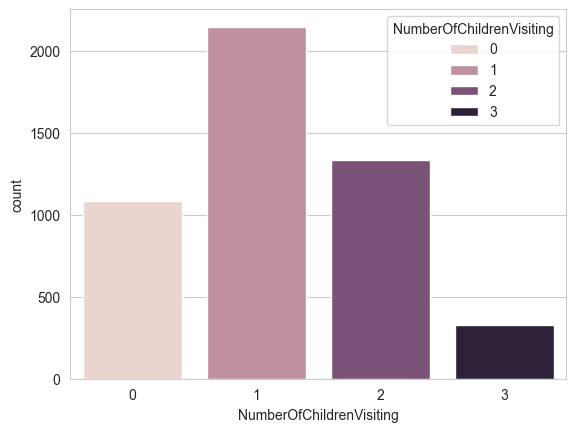

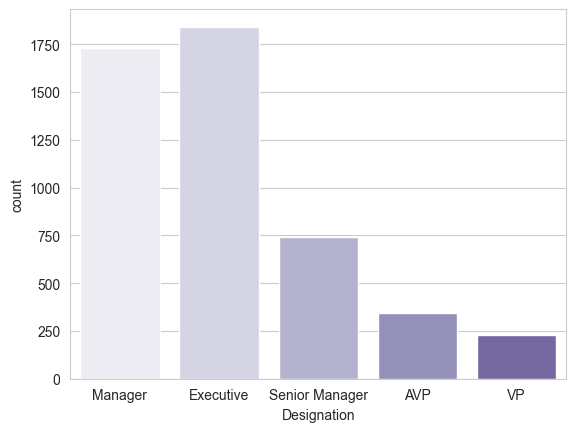

In [85]:
for i in TR2.columns:
    if TR2[i].dtypes != 'str' and i not in ['MonthlyIncome','customerID','DurationOfPitch','Age']:
        sns.countplot(x=TR[i],palette=palette,hue=TR[i])
        plt.show()

# find out influencing factors for conversion in calls ?

In [86]:
Total_conversion = TR['ProdTaken'].mean()

In [87]:
round(Total_conversion,2) # in total 15% calls are getting converted 

np.float64(0.19)

In [88]:
TR2_type = TR2.groupby('TypeofContact').agg({'ProdTaken':'mean'}).reset_index()

In [89]:
TR2_type 

,TypeofContact,ProdTaken
0,Company Invited,0.218464
1,Self Enquiry,0.175843


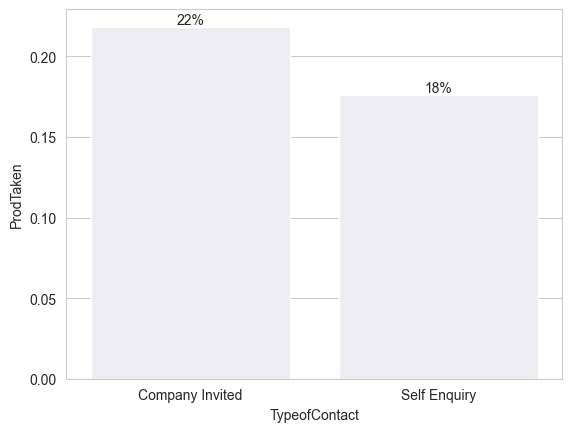

In [90]:
ax= sns.barplot(TR2_type,x='TypeofContact' , y='ProdTaken')
for i in ax.containers:
    ax.bar_label(i,fmt='{:.0%}')

In [91]:
TR2['TypeofContact'].value_counts()

TypeofContact
Self Enquiry       3465
Company Invited    1413
Name: count, dtype: int64

In [92]:
TR.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting',
       'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar',
       'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore',
       'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='object')

In [93]:
cat_TR2 = TR2.drop(['Age','MonthlyIncome','DurationOfPitch'],axis=1)

In [94]:
# for col in cat_TR2:
#     if col != 'ProdTaken':
#         group_df = cat_TR2.groupby(col)['ProdTaken'].mean().reset_index()
#         ax = sns.barplot(data=group_df, x=col, y='ProdTaken', palette=palette)
#         for i in ax.containers:
#             ax.bar_label(i, fmt='{:.0%}')
#         plt.show()

C:\Users\pc\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


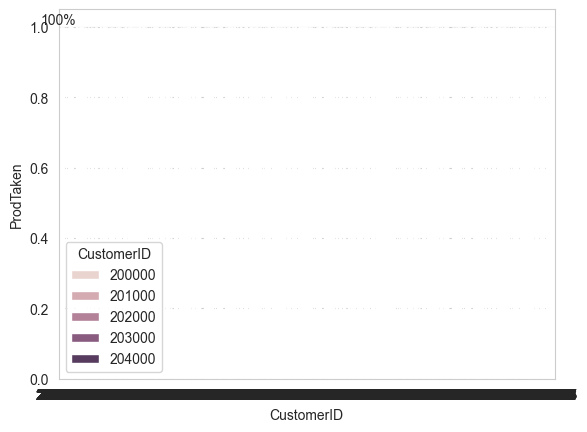

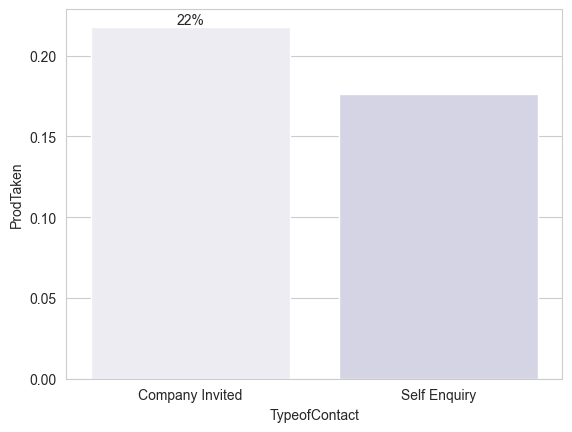

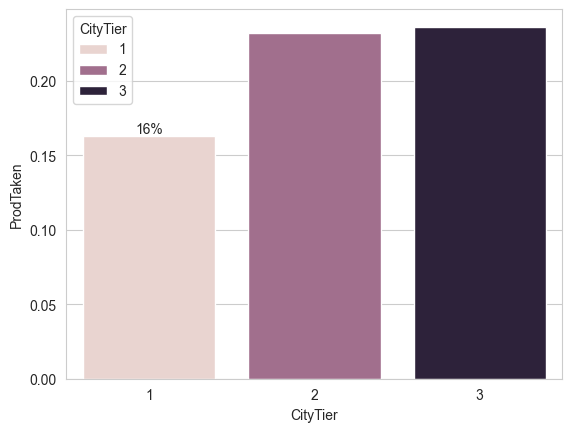

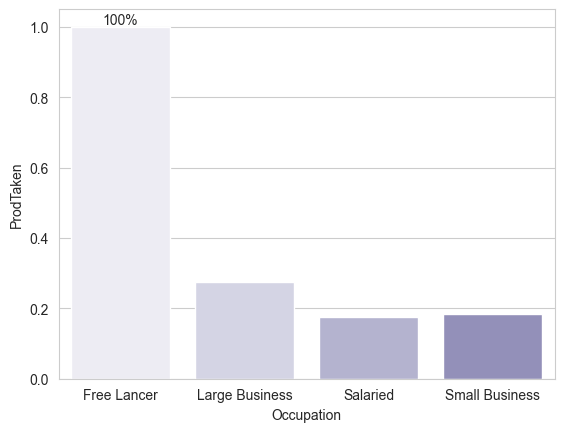

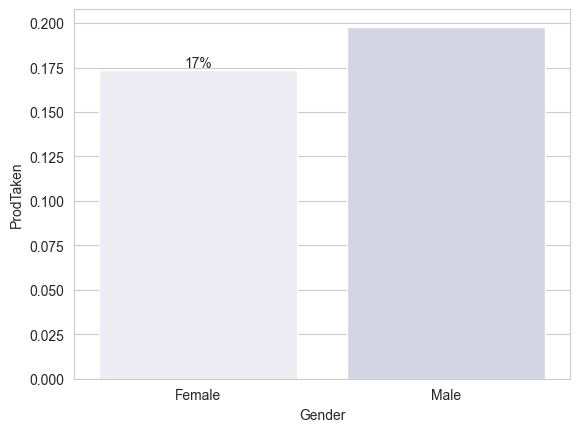

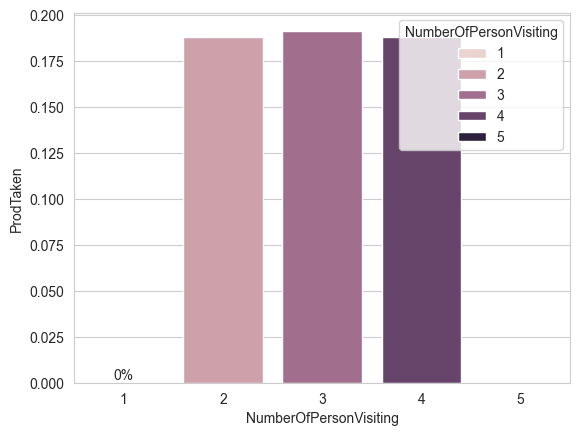

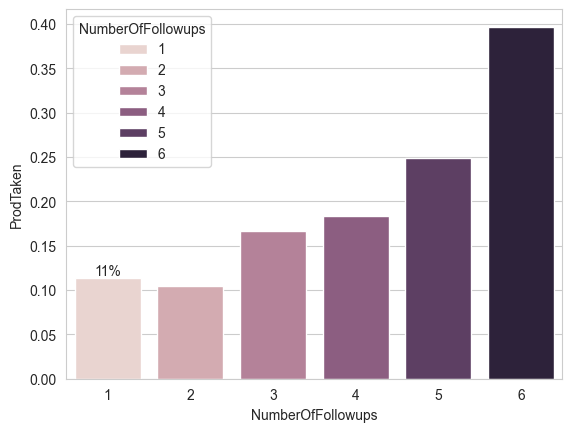

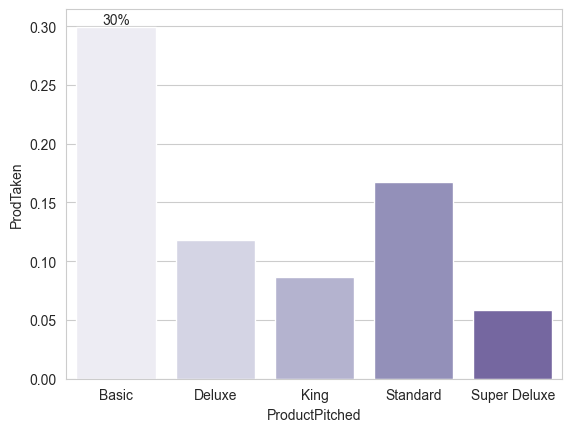

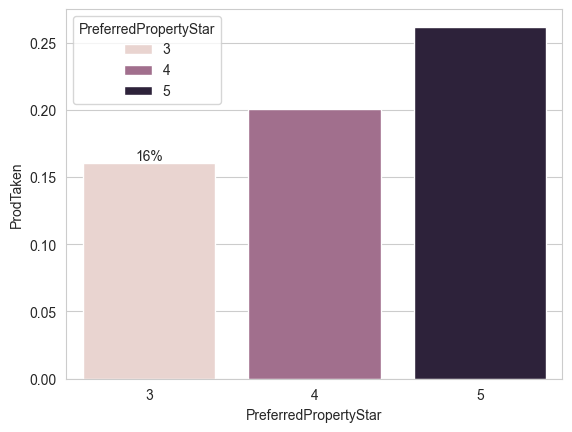

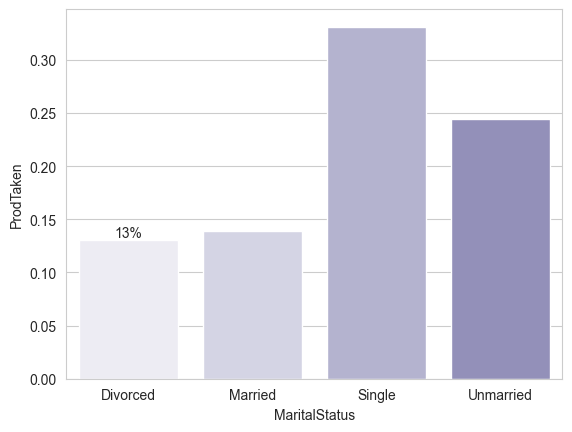

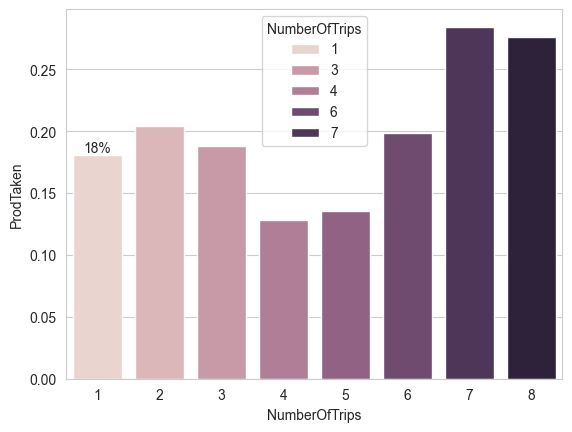

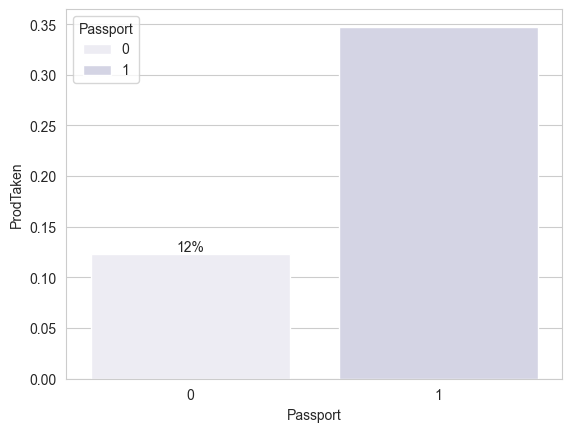

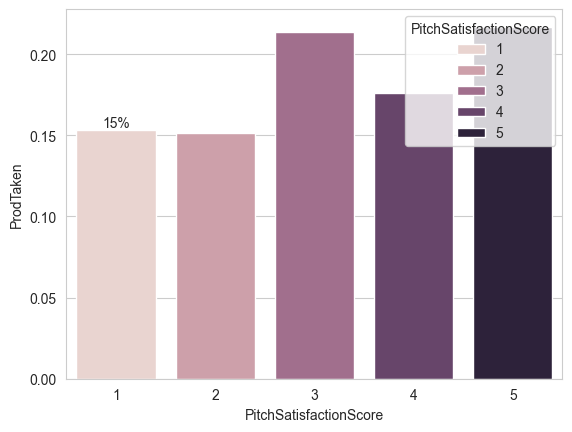

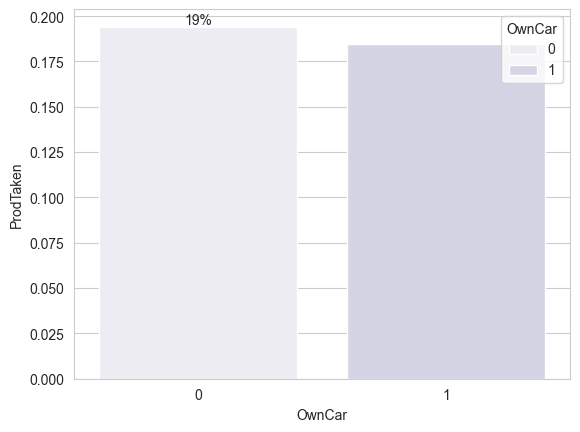

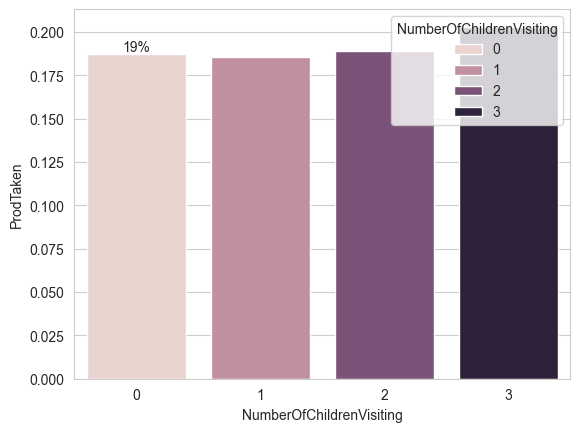

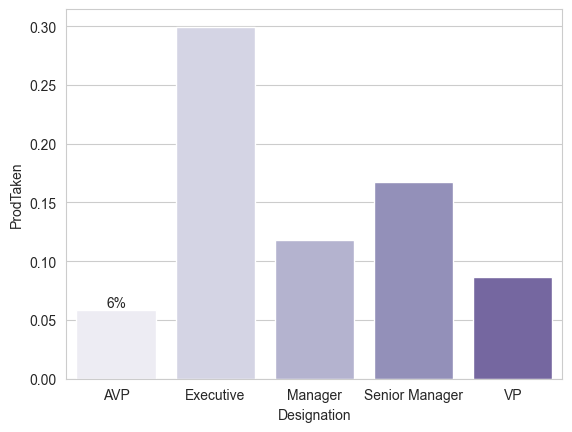

In [95]:
for col in cat_TR2:
    if col!='ProdTaken':
        group_df = cat_TR2.groupby(col).agg({'ProdTaken':'mean'}).reset_index()
        ax = sns.barplot(group_df, x=col, y='ProdTaken',hue=col , palette= palette)
        for i in ax.containers:
            ax.bar_label(i,fmt='{:.0%}')
            plt.show()

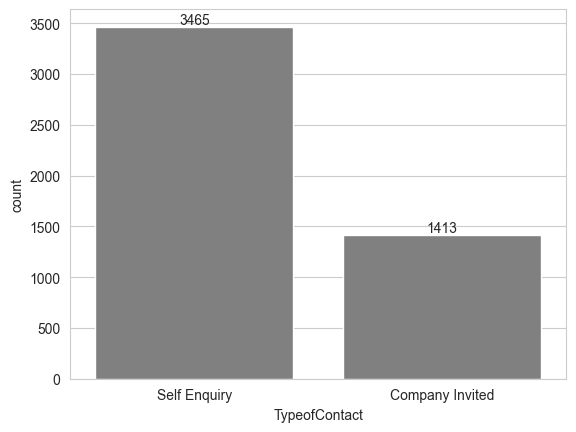

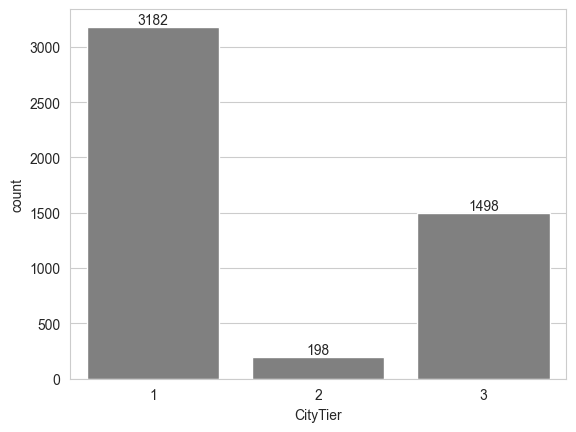

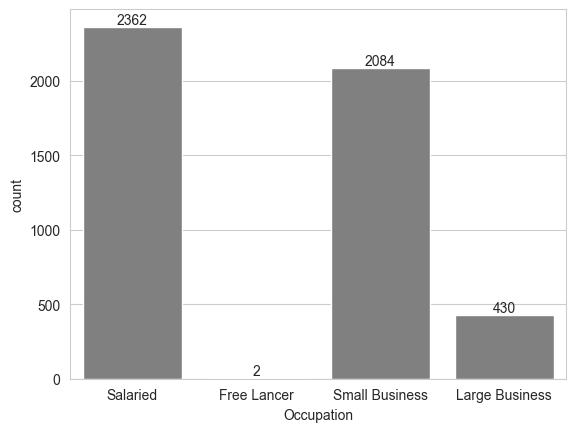

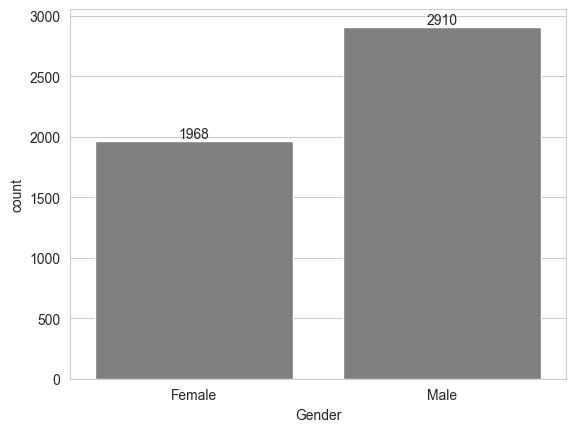

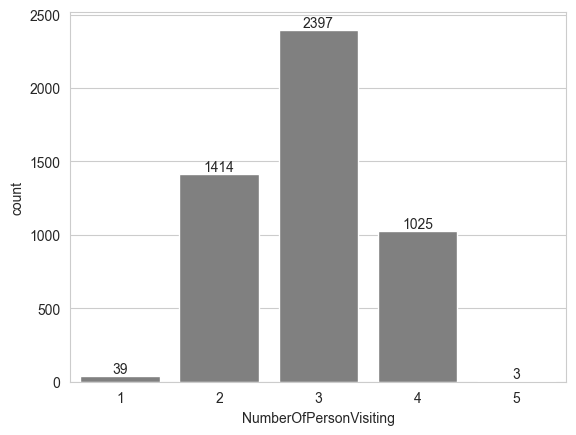

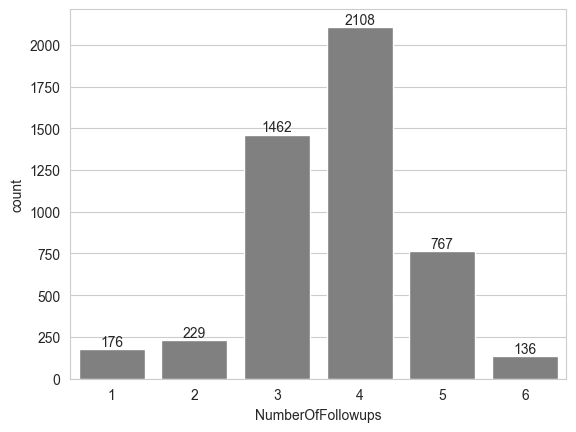

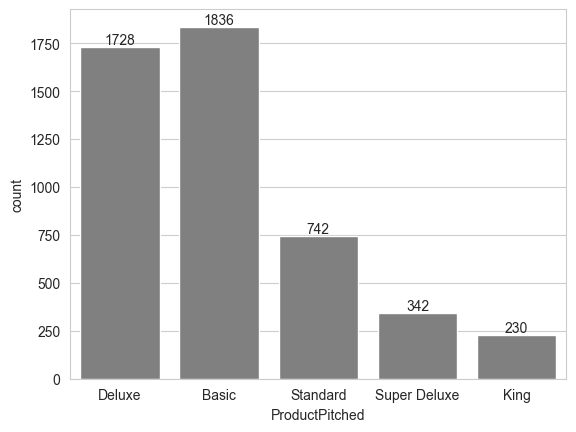

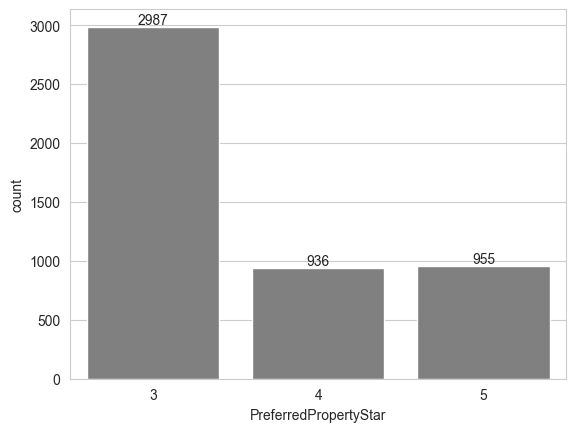

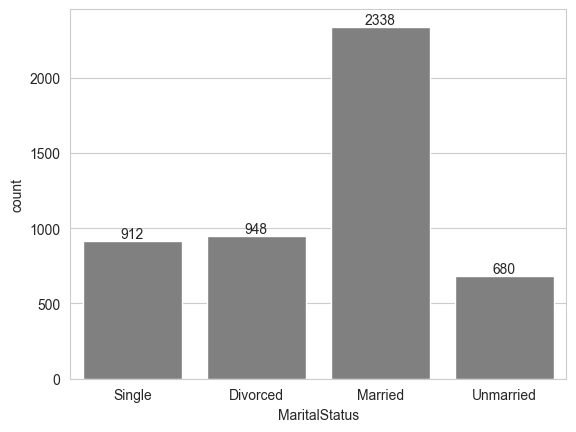

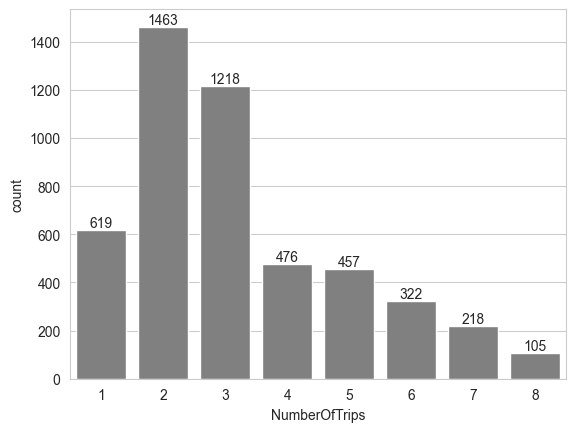

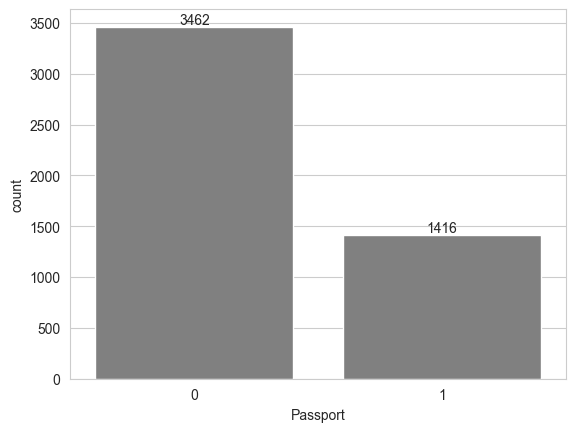

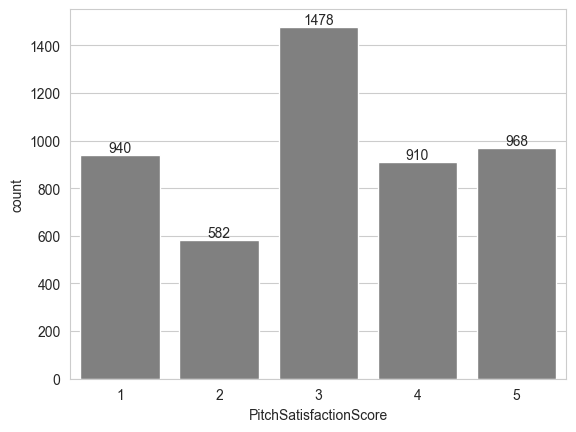

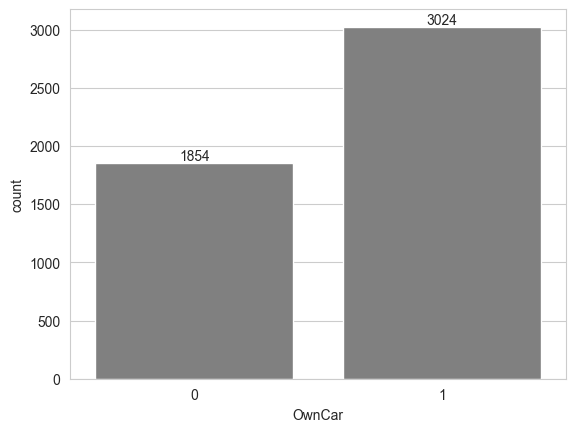

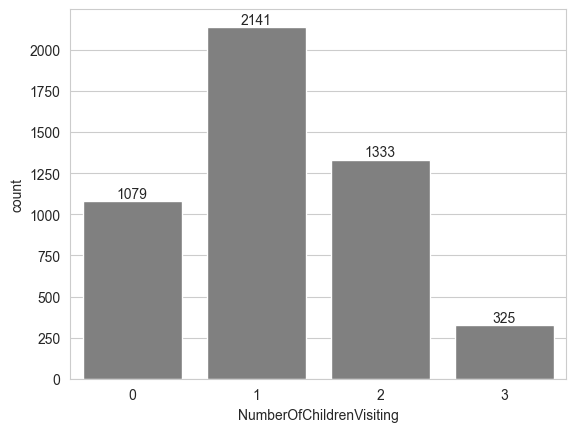

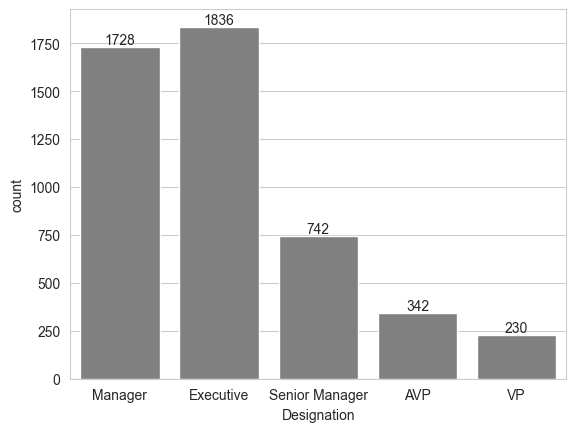

In [96]:
for col in cat_TR2:
    if col not in [ 'ProdTaken' ,'CustomerID']:
        ax=sns.countplot(cat_TR2 , x=col , color= 'grey')
        for i in ax.containers:
            ax.bar_label(i)
        plt.show()

In [97]:
TR2.columns

Index(['CustomerID', 'ProdTaken', 'Age', 'TypeofContact', 'CityTier',
       'DurationOfPitch', 'Occupation', 'Gender', 'NumberOfPersonVisiting',
       'NumberOfFollowups', 'ProductPitched', 'PreferredPropertyStar',
       'MaritalStatus', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore',
       'OwnCar', 'NumberOfChildrenVisiting', 'Designation', 'MonthlyIncome'],
      dtype='object')

In [98]:
Num_TR2 = TR2[['MonthlyIncome','DurationOfPitch','Age']]

C:\Users\pc\AppData\Local\Temp\ipykernel_13764\2448346637.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Num_TR2[col+'Segment'] = pd.cut(Num_TR2[col],bins=3 , labels=['Low','Medium','High'])


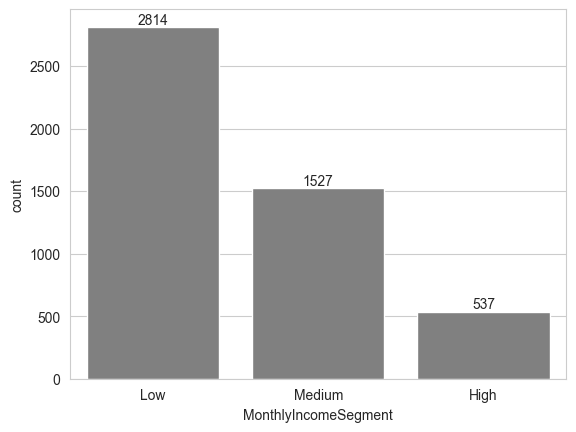

C:\Users\pc\AppData\Local\Temp\ipykernel_13764\2448346637.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Num_TR2[col+'Segment'] = pd.cut(Num_TR2[col],bins=3 , labels=['Low','Medium','High'])


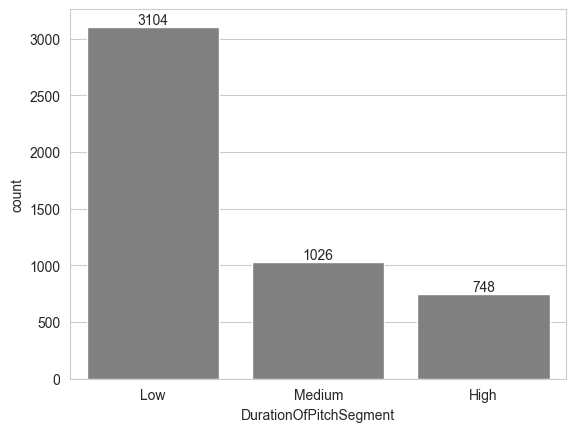

C:\Users\pc\AppData\Local\Temp\ipykernel_13764\2448346637.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Num_TR2[col+'Segment'] = pd.cut(Num_TR2[col],bins=3 , labels=['Low','Medium','High'])


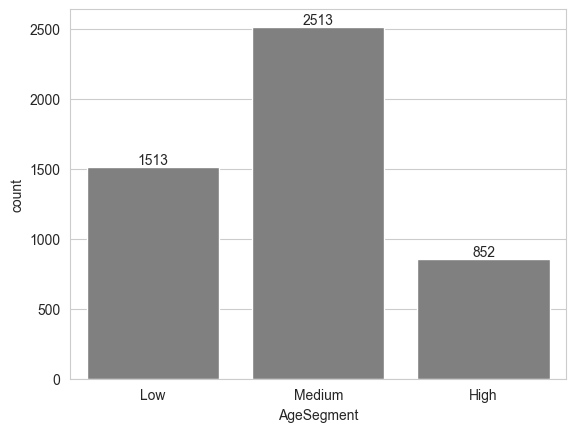

In [99]:
for col in Num_TR2:
    Num_TR2[col+'Segment'] = pd.cut(Num_TR2[col],bins=3 , labels=['Low','Medium','High'])
    ax=sns.countplot(Num_TR2 , x= col+ 'Segment',color='gray')
    for i in ax.containers:
        ax.bar_label(i)
    plt.show()

In [100]:
Num_TR2['ProdTaken']=TR2.ProdTaken

C:\Users\pc\AppData\Local\Temp\ipykernel_13764\1689540698.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Num_TR2['ProdTaken']=TR2.ProdTaken


In [101]:
for col in Num_TR2:
    if col.endswith('segment'):
        group_df = Num_TR2.groupby(col).agg({'ProdTaken':'mean'}).reset_index()
        ax=sns.batplot(group_df,x=col ,y='prodTaken',hue='ProdTaken',palette=palette)
        for i in ax.containers:
            ax.bar_label(i,fmt='{:.0%}')
            plt.show()

In [102]:
import os
os.makedirs('Travel_Report_plots',exist_ok=True)

In [103]:
plt_counter=1

In [104]:
def auto_save(event):
    global plt_counter
    filename=os.path.join('Travel_Report_plots',f'Travel_Report_plots{plt_counter}')
    event.canvas.figure.savefig(filename)
    print(f"saved:{filename}")
    plt_countar+=1

In [105]:
plt_counter = 0 # initially plot will start saving as blank with count 0
is_saving = False # if saving is true then function will not run

def auto_save(event):
    global plt_counter, is_saving
   
    if is_saving: # once is_saving is true then function will stop
        return
   
    is_saving = True
    # once the fuction will run first time then saving will true and it will not work for second iteration
   
    os.makedirs('Travel_Report_plots', exist_ok=True) # create  folder
    filename = os.path.join('Travel_Report_plots', f'plot_{plt_counter}.png') # creating path for saving file
   
    event.canvas.figure.savefig(filename) # event to save file
   
    plt_counter += 1 # name of file will increase by 1 after each and every saving is done
    is_saving = False # saving false till the time fill plots are completed


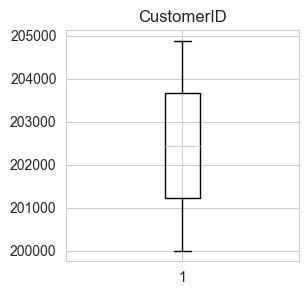

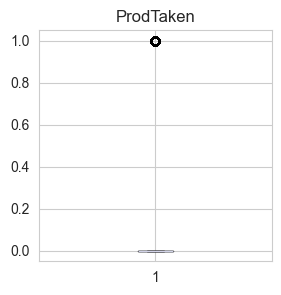

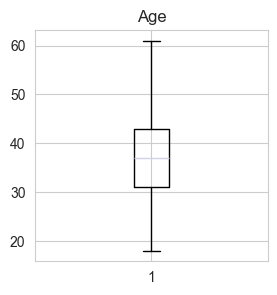

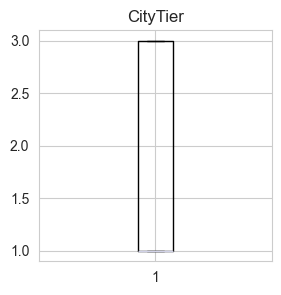

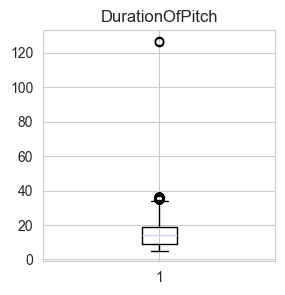

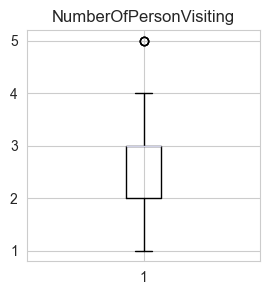

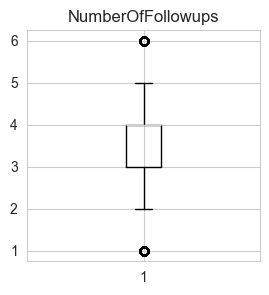

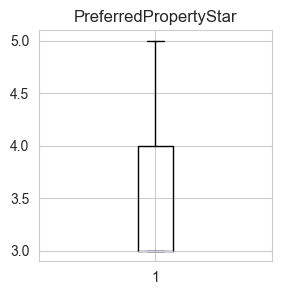

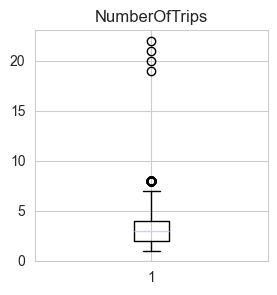

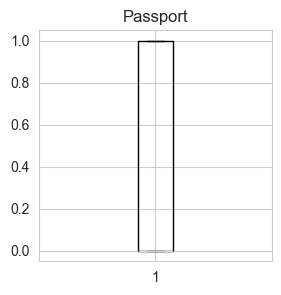

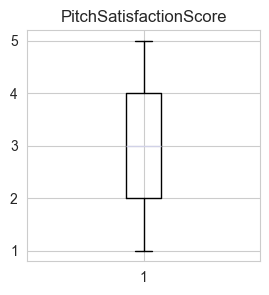

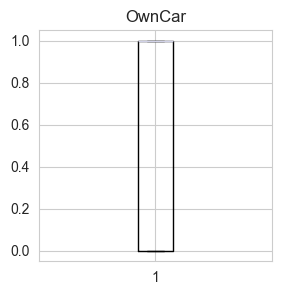

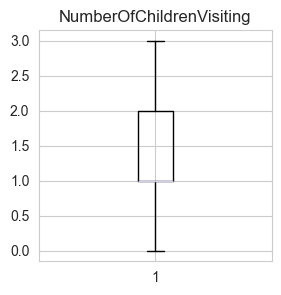

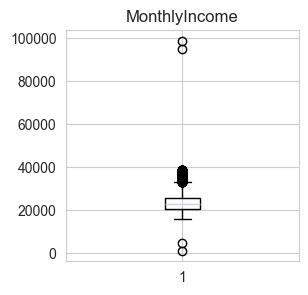

In [106]:
for col in TR.columns:
    if TR[col].dtype != 'object':
        fig, ax = plt.subplots(figsize=(3,3)) # storing plot by name of fig
        ax.boxplot(TR[col]) # create box plot
        ax.set_title(col) # give title to plot
        cid = fig.canvas.mpl_connect('draw_event', auto_save) # using def function to save plots in directory
        plt.show() # to  show plot in ipynb file